# COMP41810 Advanced Machine Learning

- **Name:** 
- **Student Number:**
- **Name:** 
- **Student Number:**
- **Name:** 
- **Student Number:** 

## Assignment 2: Learning to Walk *With Style*
Uses the PPO actor-critic method to train a neural network to allow a simple robot to learn to walk using the **Bipedal Walker** environment from the `gymnasium` package (https://gymnasium.farama.org/environments/box2d/bipedal_walker/). This assignment uses a custom version of the environment that includes some small modifications, `BipedalWalkerUCD`.

![Bipedal Walker](bipedal_walker.gif)

The **action** space is continuous where the actions are motor speed values in the [-1, 1] range for each of the 4 joints at both hips and knees.

The **observation** is a state vector consisting of hull angle speed, angular velocity, horizontal speed, vertical speed, position of joints and joints angular speed, legs contact with ground, and 10 lidar rangefinder measurements. There are no coordinates in the state vector.

The basic **reward** provides a small positive rewqard for every step forwards (left to right) the agent takes.

In this assignment we will explore different reward functions. 

### Initialisation

If using Google colab you need to install packages - comment out lines below.

In [1]:
#!apt install swig cmake ffmpeg
#!apt-get install -y xvfb x11-utils
#!pip install stable-baselines3[extra] pyglet box2d box2d-kengz
#!pip install pyvirtualdisplay PyOpenGL PyOpenGL-accelerate
#!pip install gymnasium stable_baselines3

For Google colab comment out this cell to make a virtual rendering canvas so render calls work (we still wont; see display!)

In [2]:
#import pyvirtualdisplay
#
#_display = pyvirtualdisplay.Display(visible=False,  # use False with Xvfb
#                                    size=(1400, 900))
#_ = _display.start()

Import required packages.

In [3]:
import gymnasium as gym
import stable_baselines3 as sb3
import torch

import bipedal_walker_ucd

import os
import gc  # the clean up cells call gc.collect() but gc was never imported in the template
import logging
import shutil  # for clearing old eval logs/videos if a training cell gets rerun
import pandas as pd # For data frames and data frame manipulation
pd.set_option('display.max_rows', 100)
pd.set_option('display.max_columns', 100)
pd.set_option('display.width', 1000)
import numpy as np # For general  numeric operations
from collections import deque
from pathlib import Path
import re

import imageio
from IPython.display import Image as DisplayImage, Video, display
from PIL import Image, ImageDraw
import imageio.v3 as iio

import matplotlib.pyplot as plt
%matplotlib inline

# the networks are tiny (2 layers of 64) so 1 cpu thread trains about as fast as 8
# (507 vs 554 steps/sec when i timed it), and with the fixed seed a rerun gives the exact same agent
torch.set_num_threads(1)
seed = 0

# imageio prints a warning for every video because 600px isnt a multiple of 16
# (ffmpeg rescales it to 608 wide). harmless so muting it, otherwise theres 100s of them in the output
# (this mutes imageio_ffmpeg's other warnings too, errors still show)
logging.getLogger("imageio_ffmpeg").setLevel(logging.ERROR)

### Define Utility Code

We define a custom wrapper to allow experimantion twith different rewards in the Bipedal Walker environment. This adds potential extra reward terms:

- **Action Penalty:** Encourages the agent tio be frugal in its use of actions.
- **Stability:** Encourage the hull to stay horizontal.
- **Smoothness:** Encourages similar action from one step to the next.
- **Speed:** Encourages the agent to move as fast as possible. 

Each of these different com-oentnts of the reward can have a different weight associated with it. These are passed as parameters to the reward wrapper.

- `action_penalty_weight`
- `stability_weight`
- `speed_weight`
- `smoothness_weight`


In [4]:
class CustomRewardWrapper(gym.Wrapper):
    def __init__(self, env, window=20,
                 action_penalty_weight = 0.0,
                 stability_weight=0.0,
                 smoothness_weight = 0.0,
                 speed_weight=0.0
                 ):
        super().__init__(env)
        self.window = window
        self.action_penalty_weight = action_penalty_weight
        self.stability_weight = stability_weight
        self.smoothness_weight = smoothness_weight
        self.speed_weight = speed_weight

        self.prev_action = np.zeros(env.action_space.shape)
        self.hip1_history = deque(maxlen=window)
        self.hip2_history = deque(maxlen=window)

    def step(self, action):
        obs, base_reward, terminated, truncated, info = self.env.step(action)

        # --- Extract state ---
        hull = self.env.unwrapped.hull
        hull_angle   = hull.angle
        hull_vel_x   = hull.linearVelocity[0]
        hull_vel_y   = hull.linearVelocity[1]
        hull_height  = hull.position.y

        # obs layout is in bipedal_walker_ucd.py step(): leg 1 = obs[4..8], leg 2 = obs[9..13]
        # the template had leg 2 shifted by one (obs[10] is hip2 SPEED not angle etc) - fixed here.
        # none of these are used in the task 1 reward anyway but they are in task 2
        vel         = obs[2]
        hip1_angle  = obs[4]
        hip2_angle  = obs[9]
        hip1_vel    = obs[5]
        hip2_vel    = obs[10]
        knee1_angle = obs[6]   # note the env adds +1 to knee angles
        knee2_angle = obs[11]
        knee1_vel   = obs[7]
        knee2_vel   = obs[12]

        # --- Action Penalty ----
        # normalized to about -50.0 using heuristic, more optimal agent should spend less
        action_penalty = 0
        for a in action:
            action_penalty -= 0.00035 * bipedal_walker_ucd.MOTORS_TORQUE * np.clip(np.abs(a), 0, 1)
        action_penalty = action_penalty

        # --- Stability ---
        stability = -abs(hull_angle)

        # --- Smoothness ---
        smoothness = -np.sum(np.abs(action - self.prev_action))

        # --- Speed targeting ---
        speed = hull_vel_x

        # --- Total reward ---
        modified_reward = (
            base_reward
            + action_penalty * self.action_penalty_weight
            + stability * self.stability_weight
            + smoothness * self.smoothness_weight
            + speed * self.speed_weight
        )

        # --- Reward components for TensorBoard ---
        info["reward_components"] = {
            "base":              base_reward,
            "action_penalty":    action_penalty,
            "stability":         stability,
            "smoothness":        smoothness,
            "speed":             speed,
            "total":             modified_reward,
        }

        self.prev_action = action.copy()
        return obs, modified_reward, terminated, truncated, info

    def reset(self, **kwargs):
        self.prev_action = np.zeros(self.env.action_space.shape)
        self.hip1_history.clear()
        self.hip2_history.clear()
        return self.env.reset(**kwargs)

The `VideoEvalCallback` writes out the components of the reward function defined above and also records videos of agent behaviour.

In [5]:

class VideoEvalCallback(sb3.common.callbacks.BaseCallback):
    def __init__(
        self,
        eval_env: gym.Env,
        eval_freq: int = 10_000,
        n_eval_episodes: int = 1,
        video_folder: str = "./eval_videos",
        video_length: int = 1000,
        tensorboard_log: str = "./tb_logs",
        tb_video_every: int = 4,
        tb_video_scale: int = 2,
        verbose: int = 1,
    ):
        super().__init__(verbose)
        self.eval_env = eval_env
        self.eval_freq = eval_freq
        self.n_eval_episodes = n_eval_episodes
        self.video_folder = video_folder
        self.video_length = video_length        # max frames recorded per evaluation video
        self.tensorboard_log = tensorboard_log
        self.tb_video_every = tb_video_every    # TensorBoard copy keeps every Nth frame (0 = no TensorBoard video)...
        self.tb_video_scale = tb_video_scale    # ...downscaled by this factor
        self.writer = None                      # opened on first use, see _get_writer()
        self.eval_count = 0
        os.makedirs(video_folder, exist_ok=True)

    def _get_writer(self):
        # Opened lazily so that creating a callback (or re-running its cell) doesn't leave a writer open
        if self.writer is None:
            self.writer = torch.utils.tensorboard.SummaryWriter(log_dir=self.tensorboard_log)
        return self.writer

    def _on_step(self) -> bool:
        if self.n_calls % self.eval_freq == 0:
            self._run_eval()
        return True

    def _run_eval(self):
        self.eval_count += 1
        episode_rewards = []
        component_totals = {}
        tb_frames = []  # small copies of some frames, for TensorBoard
        video_path = os.path.join(
            self.video_folder, f"eval_{self.eval_count}_step_{self.num_timesteps}.mp4"
        )

        for episode in range(self.n_eval_episodes):
            obs, _ = self.eval_env.reset()
            done = False
            total_reward = 0.0
            ep_components = {}
            # Episode 0 is recorded: frames are written straight to the mp4 rather than kept in memory
            video_writer = imageio.get_writer(video_path, fps=30) if episode == 0 else None
            n_frames = 0

            try:
                while not done:
                    if video_writer is not None and n_frames < self.video_length:
                        frame = self.eval_env.render()
                        if frame is not None:
                            video_writer.append_data(frame)
                            if self.tb_video_every and n_frames % self.tb_video_every == 0:
                                # render() returns a view into the whole scrolled canvas;
                                # .copy() keeps only this small frame, not the canvas
                                s = self.tb_video_scale
                                tb_frames.append(frame[::s, ::s].copy())
                            n_frames += 1

                    action, _ = self.model.predict(obs, deterministic=True)
                    obs, reward, terminated, truncated, info = self.eval_env.step(action)
                    total_reward += reward
                    done = terminated or truncated

                    components = info.get("reward_components", {})
                    for key, val in components.items():
                        ep_components[key] = ep_components.get(key, 0.0) + val
            finally:
                if video_writer is not None:
                    video_writer.close()  # also stops the ffmpeg process if training is interrupted

            episode_rewards.append(total_reward)

            for key, val in ep_components.items():
                component_totals[key] = component_totals.get(key, 0.0) + val

        mean_reward = np.mean(episode_rewards)
        std_reward  = np.std(episode_rewards)

        writer = self._get_writer()
        writer.add_scalar("eval/mean_reward", mean_reward, self.num_timesteps)
        writer.add_scalar("eval/std_reward",  std_reward,  self.num_timesteps)

        for key, total in component_totals.items():
            mean_val = total / self.n_eval_episodes
            writer.add_scalar(
                f"eval/reward_components/{key}", mean_val, self.num_timesteps
            )

        if self.verbose:
            print(f"\n[Eval @ {self.num_timesteps} steps]")
            print(f"  Mean reward: {mean_reward:.2f} +/- {std_reward:.2f}")
            for key, total in component_totals.items():
                print(f"    {key:>20s}: {total / self.n_eval_episodes:.4f}")
            print(f"  Video saved to {video_path}")

        if tb_frames:
            self._log_video_to_tensorboard(tb_frames)

    def _log_video_to_tensorboard(self, frames: list):
        # (1, T, C, H, W) uint8 -- add_video rescales uint8 itself, so no float32 copy is needed here
        video_array = np.stack(frames).transpose(0, 3, 1, 2)[np.newaxis]
        writer = self._get_writer()
        writer.add_video(
            "eval/agent_behaviour",
            video_array,
            global_step=self.num_timesteps,
            fps=max(1, round(30 / self.tb_video_every)),
        )
        writer.flush()

    def close(self):
        """Close the TensorBoard writer. Done automatically when training finishes normally;
        call it yourself after a manual evaluation or an interrupted learn()."""
        if self.writer is not None:
            self.writer.close()
            self.writer = None

    def _on_training_end(self):
        self.close()

A function to create visual summaries of videos saved for easy viewing. (Thanks to Gareth Morgan for this function)

In [6]:
def create_quick_frame_summary(video_path, n_samples=10):
    video_path = Path(video_path)
    output_dir = Path(video_path.parent / "frame_summaries")
    
    output_dir.mkdir(parents=True, exist_ok=True)

    frames = iio.imread(video_path)
    n_frames = len(frames)
    picks = sorted(
        set(int(round(i * (n_frames - 1) / max(n_samples - 1, 1))) for i in range(n_samples))
    )

    selected = [Image.fromarray(frames[i]) for i in picks]
    width, height = selected[0].size
    label_height = 28
    canvas = Image.new("RGB", (width * len(selected), height + label_height), color=(20, 20, 20))
    draw = ImageDraw.Draw(canvas)

    for idx, (frame_idx, frame_img) in enumerate(zip(picks, selected)):
        x = idx * width
        canvas.paste(frame_img, (x, label_height))
        draw.text((x + 10, 6), f"frame {frame_idx}", fill=(255, 255, 255))

    summary_path = output_dir / f"{video_path.stem}_summary.jpg"
    canvas.save(summary_path, quality=90)
    return summary_path


def select_evenly_spaced(folder, n_select=5, pattern=r"eval_(\d+)_step_(\d+)\.mp4$"):
   
    """Return n_select video paths evenly spaced by index, including first and last."""
    regex = re.compile(pattern)
    videos = []
    for p in Path(folder).iterdir():
        m = regex.match(p.name)
        if m:
            videos.append((int(m.group(1)), int(m.group(2)), p))

    # Sort numerically by index X (not alphabetically)
    videos.sort(key=lambda v: v[0])

    n = len(videos)
    if n == 0:
        return []
    if n <= n_select:
        return [v[2] for v in videos]

    # Evenly spaced positions from 0 to n-1 inclusive
    positions = [round(i * (n - 1) / (n_select - 1)) for i in range(n_select)]
    positions = sorted(set(positions))  # guard against duplicates
    return [videos[i][2] for i in positions]


### Task 1 - Run A Custom Reward Wegith Experiment
Create an instance of the **BipedalWalkerUCD** environment and add a `CustomRewardWrapper` defining the reward mix that will be used in the experiment. Experiment with using different weights in the reward function.

We define a set of utility values used throughout the experiment.

In [7]:
time_limit = 5000 # A time out for episodes (avoids infinte runs)
eval_freq = 5000 # Frequency with which evlaution (and generation of evaluation vidoe) is executed
n_eval_episodes = 3 # Number of evalaution episodes across which scores are generated
tb_log_path = './log_tb_bipedal/'
eval_log_path = './logs_bipedal/'
eval_video_base_path = Path('./eval_videos/')
run_name = "Reward_Exploration"
eval_video_path = eval_video_base_path / run_name
tb_log_name = run_name

# ppo settings the template suggests. kept in one dict so every agent in this notebook uses exactly the same ones
# (so between runs only the reward changes, plus task 2 trains for 1M steps instead of 500k)
ppo_params = dict(
    batch_size = 64,          # minibatch size for each gradient step
    clip_range = 0.2,         # clips the new/old action probability ratio to 0.8..1.2 in the loss, so theres no gain
                              # from changing the policy more than ~20% per update (the "proximal" bit)
    ent_coef = 0.001,         # small bonus for keeping the policy random-ish -> exploration
    gae_lambda = 0.95,        # bias/variance tradeoff for the advantage estimate
    gamma = 0.99,             # discount, ~100 step horizon (2 sec of sim)
    learning_rate = 0.00025,
    n_steps = 2048,           # steps collected before each update
    n_epochs = 10,            # passes over those 2048 steps per update
)
os.makedirs("./agents", exist_ok = True)   # agent.save() warns if the folder isnt there yet

#### Baseline Agent (all weights = 0)
Before changing any weights I train one agent on just the plain environment reward (all four extra weights at 0), so there is something to compare the gait against in Task 1 and Task 3. Same PPO settings and seed as the other runs. The eval printouts are switched off for this one (`verbose=0`) to keep the notebook shorter; its eval numbers still go to TensorBoard and are plotted in Task 3.

In [8]:
%%time
baseline_run_name = "Baseline"

# CustomRewardWrapper with nothing passed = all weights 0.0 -> reward is just the env one
# (130*dx/SCALE for moving right, and that step's reward becomes -100 if the hull touches the ground
#  or it walks off the left edge)
env = bipedal_walker_ucd.BipedalWalkerUCD(render_mode="rgb_array")
env = CustomRewardWrapper(env)
env = gym.wrappers.TimeLimit(env, max_episode_steps = time_limit)

eval_env = bipedal_walker_ucd.BipedalWalkerUCD(render_mode="rgb_array")
eval_env = CustomRewardWrapper(eval_env)
eval_env = gym.wrappers.TimeLimit(eval_env, max_episode_steps = time_limit)
eval_env.reset(seed = seed + 1)   # seed the eval terrains once, so the eval curve is the same if this gets rerun

agent = sb3.PPO("MlpPolicy", env, **ppo_params, tensorboard_log = tb_log_path, verbose = 0, seed = seed)

# if this cell gets rerun, wipe the old eval logs + videos first, otherwise both runs end up in the same plot
shutil.rmtree(os.path.join(tb_log_path, baseline_run_name + "_eval"), ignore_errors = True)
shutil.rmtree(eval_video_base_path / baseline_run_name, ignore_errors = True)

video_callback = VideoEvalCallback(
    eval_env = eval_env,
    eval_freq = eval_freq,
    n_eval_episodes = n_eval_episodes,
    video_folder = eval_video_base_path / baseline_run_name,
    tensorboard_log = os.path.join(tb_log_path, baseline_run_name + "_eval"),  # own folder per run so the eval curves dont get mixed up
    tb_video_every = 0,   # no video copy in tensorboard, see the task 1 callback cell for why. mp4s still get saved
    verbose = 0,
)

agent.learn(total_timesteps = 500_000, callback = video_callback, tb_log_name = baseline_run_name)
agent.save("./agents/" + baseline_run_name)

CPU times: total: 19min 31s
Wall time: 23min 14s


Processing eval_1_step_5000.mp4


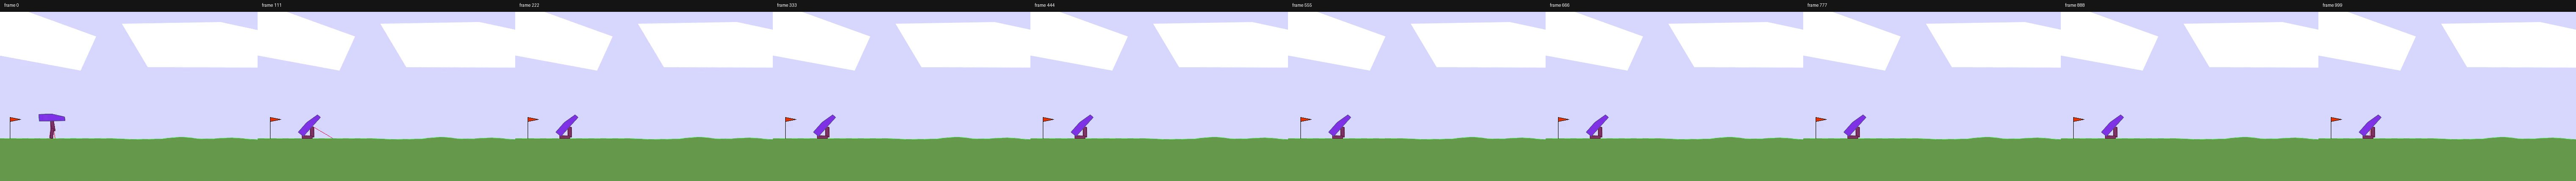

Processing eval_100_step_500000.mp4


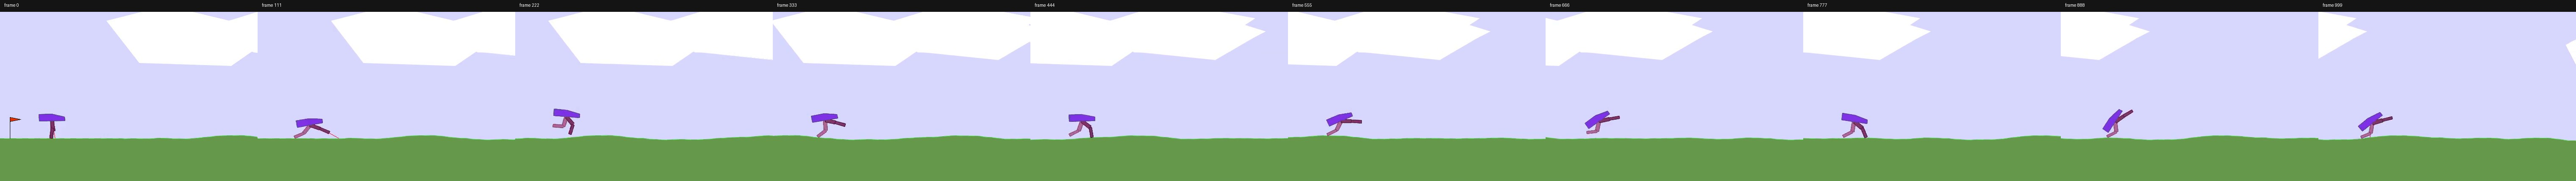

1696

In [9]:
# first and last eval videos of the baseline (frame strips)
for video_path in select_evenly_spaced(eval_video_base_path / baseline_run_name, n_select = 2):
    print(f"Processing {video_path.name}")
    summary_path = create_quick_frame_summary(video_path)
    display(DisplayImage(filename=str(summary_path)))

# tidy up same as the other runs
agent.logger.close()
video_callback.close()
env.close()
eval_env.close()
del agent, env, eval_env, video_callback
gc.collect()

#### Create the Training Environment
Experiment with different weights for different compoennts of the reward function. 

In [10]:
# task 1 mix. each term gets added to the base reward every step (see CustomRewardWrapper above)
action_penalty_weight = 1.0   # torque cost, 1.0 = same size as the cost in the normal gym BipedalWalker
stability_weight = 0.5        # -|hull angle| per step -> stay level
smoothness_weight = 0.05       # -sum|a_t - a_(t-1)|, can be up to 8 a step so this has to be small
speed_weight = 0.0            # hull x velocity per step. adds up to ~50 x distance so it acts like extra distance reward

Create the environment.

In [11]:
env = bipedal_walker_ucd.BipedalWalkerUCD(render_mode="rgb_array")
env = CustomRewardWrapper(env,
                          action_penalty_weight = action_penalty_weight,
                          stability_weight = stability_weight,
                          smoothness_weight = smoothness_weight,
                          speed_weight = speed_weight
                         )
env = gym.wrappers.TimeLimit(env,
                                max_episode_steps = time_limit)

#### Create an Agent
Create an agent that controls the robot. A `PPO` agent with the following hyper-parameters should work well (although you can experiment):
- `batch_size = 64`
- `clip_range = 0.2`
- `ent_coef = 0.001`
- `gae_lambda =  0.95`
- `gamma = 0.99`
- `learning_rate = 0.00025`
- `n_steps = 2048`
- `n_epochs = 10`

We also recommend enabling **tensorboard** monitoring of the training process.

In [12]:
# MlpPolicy = seperate actor and critic nets, 2 hidden layers of 64 each (sb3 default)
# verbose=0 because the callback below already prints eval results, the ppo table every 2048 steps is a lot
agent = sb3.PPO("MlpPolicy", env, **ppo_params, tensorboard_log = tb_log_path, verbose = 0, seed = seed)

Examine the actor and critic network architectures.

In [13]:
print(agent.policy)

ActorCriticPolicy(
  (features_extractor): FlattenExtractor(
    (flatten): Flatten(start_dim=1, end_dim=-1)
  )
  (pi_features_extractor): FlattenExtractor(
    (flatten): Flatten(start_dim=1, end_dim=-1)
  )
  (vf_features_extractor): FlattenExtractor(
    (flatten): Flatten(start_dim=1, end_dim=-1)
  )
  (mlp_extractor): MlpExtractor(
    (policy_net): Sequential(
      (0): Linear(in_features=24, out_features=64, bias=True)
      (1): Tanh()
      (2): Linear(in_features=64, out_features=64, bias=True)
      (3): Tanh()
    )
    (value_net): Sequential(
      (0): Linear(in_features=24, out_features=64, bias=True)
      (1): Tanh()
      (2): Linear(in_features=64, out_features=64, bias=True)
      (3): Tanh()
    )
  )
  (action_net): Linear(in_features=64, out_features=4, bias=True)
  (value_net): Linear(in_features=64, out_features=1, bias=True)
)


#### Create a Callback
Create an evaluation callback that is called every at regular intervals and renders the episode. First create an evaluation environment with equivalent wrappers then create the callbacks.

In [14]:
eval_env = bipedal_walker_ucd.BipedalWalkerUCD(render_mode="rgb_array")
eval_env = CustomRewardWrapper(eval_env,
                          action_penalty_weight = action_penalty_weight,
                          stability_weight = stability_weight,
                          smoothness_weight = smoothness_weight,
                          speed_weight = speed_weight
                         )
eval_env = gym.wrappers.TimeLimit(eval_env,
                                max_episode_steps = time_limit)
eval_env.reset(seed = seed + 1)   # seed the eval terrains once so the eval curve is repeatable

eval_log_path = eval_log_path

# start clean if this gets rerun (old eval curves/videos would get mixed in with the new ones)
shutil.rmtree(os.path.join(tb_log_path, run_name + "_eval"), ignore_errors = True)
shutil.rmtree(eval_video_path, ignore_errors = True)

video_callback = VideoEvalCallback(
    eval_env = eval_env,
    eval_freq = eval_freq,
    n_eval_episodes = n_eval_episodes,
    video_folder = eval_video_path,
    tensorboard_log = os.path.join(tb_log_path, run_name + "_eval"),  # own folder per run, otherwise the eval curves of all runs land in one
    tb_video_every = 0,   # turns off the tensorboard copy of the video. torch's add_video needs moviepy 1.x (not installed),
                          # and on windows that route fails anyway (it cant reopen its temp gif). the mp4s are unaffected
    verbose=1,
)

#### Run the Agent Training Process
Train the model for a large number of timesteps (500,000 timesteps will probably work well).

In [15]:
%%time
# 500k steps (brief says good behaviour shows up around there). eval (3 episodes + video) every 5000 steps via the callback
agent.learn(total_timesteps = 500_000, callback = video_callback, tb_log_name = tb_log_name)


[Eval @ 5000 steps]
  Mean reward: -111.94 +/- 0.65
                    base: -105.0910
          action_penalty: -0.5586
               stability: -12.2605
              smoothness: -3.2915
                   speed: -57.3000
                   total: -111.9444
  Video saved to eval_videos\Reward_Exploration\eval_1_step_5000.mp4



[Eval @ 10000 steps]
  Mean reward: -126.13 +/- 0.89
                    base: -107.6900
          action_penalty: -2.1480
               stability: -31.9922
              smoothness: -5.9183
                   speed: -88.3841
                   total: -126.1301
  Video saved to eval_videos\Reward_Exploration\eval_2_step_10000.mp4



[Eval @ 15000 steps]
  Mean reward: -121.11 +/- 2.12
                    base: -106.8816
          action_penalty: -1.9586
               stability: -23.9804
              smoothness: -5.6059
                   speed: -78.8923
                   total: -121.1108
  Video saved to eval_videos\Reward_Exploration\eval_3_step_15000.mp4



[Eval @ 20000 steps]
  Mean reward: -255.80 +/- 150.65
                    base: -63.8108
          action_penalty: -59.5697
               stability: -264.0912
              smoothness: -7.4006
                   speed: 38.3315
                   total: -255.7978
  Video saved to eval_videos\Reward_Exploration\eval_4_step_20000.mp4



[Eval @ 25000 steps]
  Mean reward: -513.79 +/- 23.17
                    base: 0.2313
          action_penalty: -225.1089
               stability: -576.9675
              smoothness: -8.6996
                   speed: 3.1851
                   total: -513.7900
  Video saved to eval_videos\Reward_Exploration\eval_5_step_25000.mp4



[Eval @ 30000 steps]
  Mean reward: -567.80 +/- 6.43
                    base: 0.3592
          action_penalty: -241.5175
               stability: -652.5603
              smoothness: -7.1185
                   speed: 4.6111
                   total: -567.7970
  Video saved to eval_videos\Reward_Exploration\eval_6_step_30000.mp4


... (91 outputs left out)


[Eval @ 490000 steps]
  Mean reward: 85.00 +/- 101.00
                    base: 263.9732
          action_penalty: -80.5561
               stability: -116.9189
              smoothness: -799.2135
                   speed: 3431.3923
                   total: 84.9970
  Video saved to eval_videos\Reward_Exploration\eval_98_step_490000.mp4



[Eval @ 495000 steps]
  Mean reward: 164.97 +/- 5.29
                    base: 364.2138
          action_penalty: -96.8175
               stability: -110.4381
              smoothness: -944.0570
                   speed: 4202.5091
                   total: 164.9744
  Video saved to eval_videos\Reward_Exploration\eval_99_step_495000.mp4



[Eval @ 500000 steps]
  Mean reward: 87.45 +/- 115.82
                    base: 234.3305
          action_penalty: -71.8319
               stability: -78.9964
              smoothness: -710.9306
                   speed: 3089.2656
                   total: 87.4539
  Video saved to eval_videos\Reward_Exploration\eval_100_step_500000.mp4


CPU times: total: 21min 4s
Wall time: 24min 39s


Connect to the tensorboard log using **TensorBoard** from the command line to view training progress:

    `tensorboard --logdir ./log_tb_bipedal/` # Change to whatever is stored in tb_log_path

Then open TensorBoard in a browser, typically located at:

`http://localhost:6006/`

#### View Video Summaries

Visualise some summaries of saved videos.

Processing eval_1_step_5000.mp4


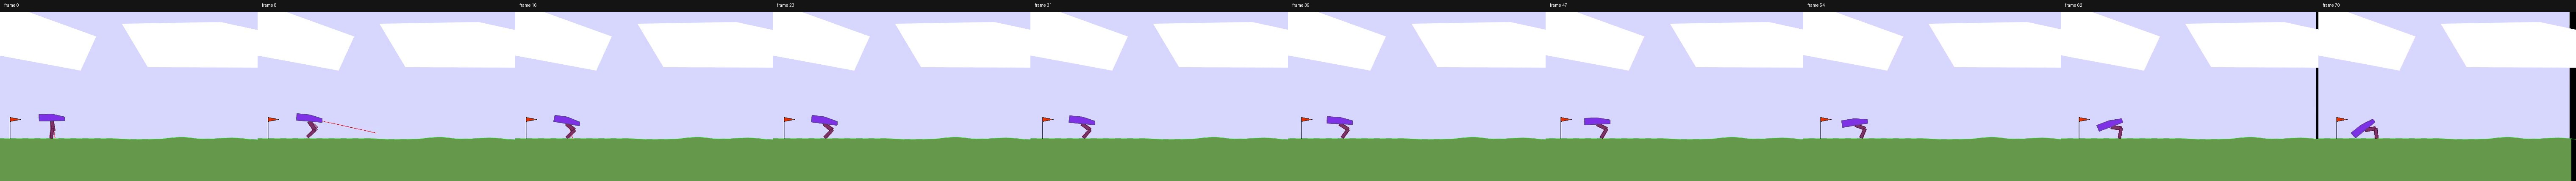

Processing eval_26_step_130000.mp4


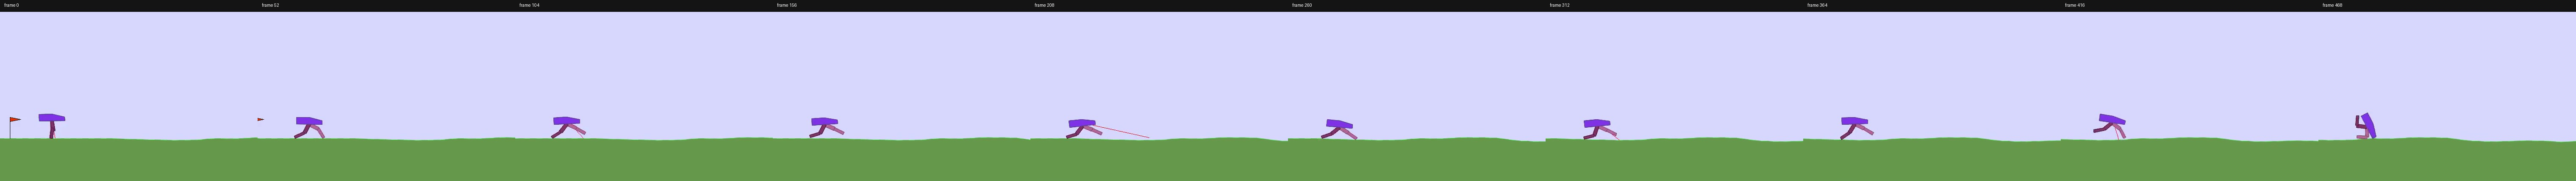

Processing eval_51_step_255000.mp4


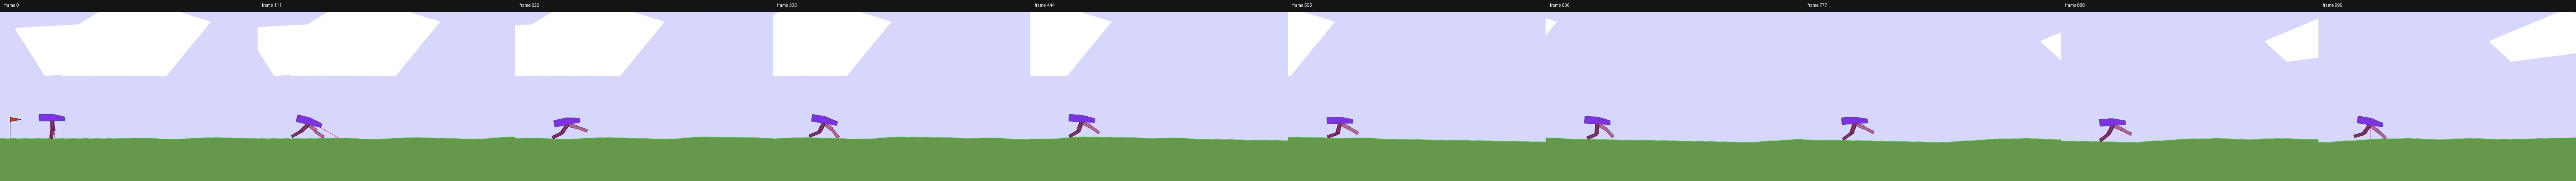

Processing eval_75_step_375000.mp4


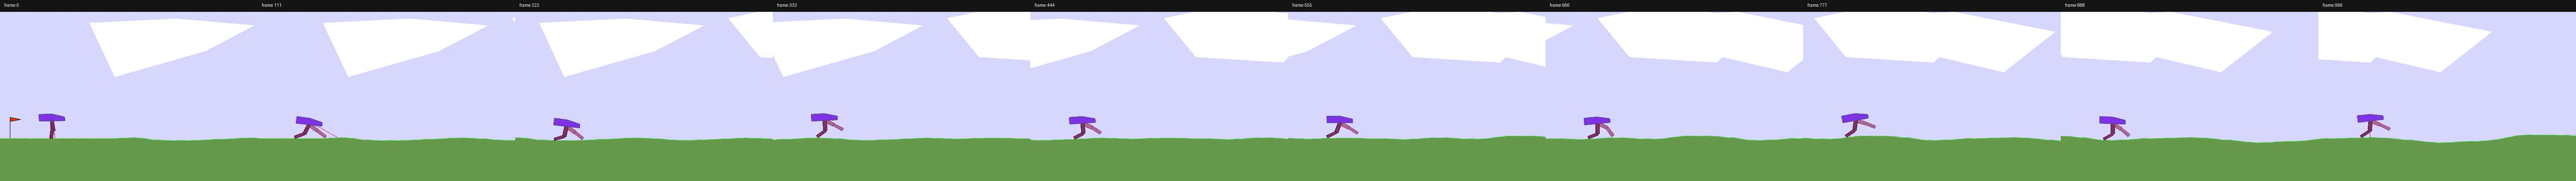

Processing eval_100_step_500000.mp4


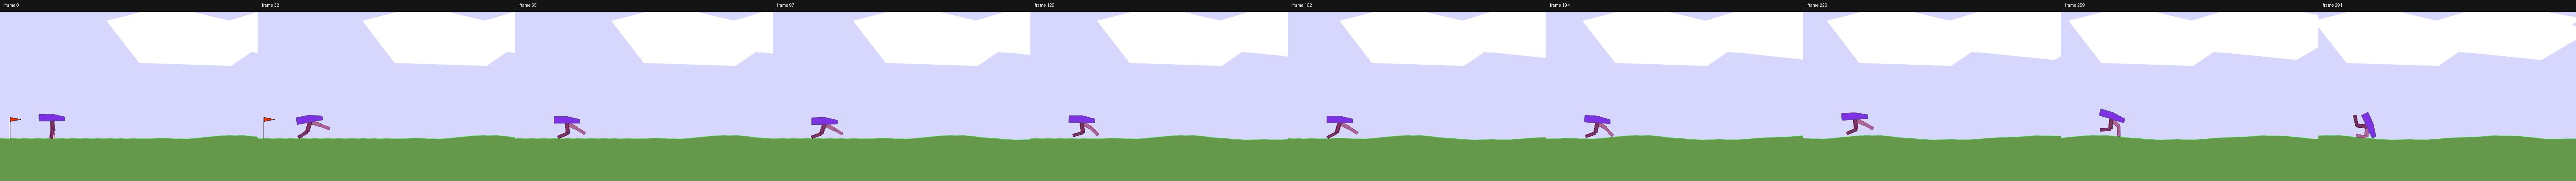

In [16]:
for video_path in select_evenly_spaced(eval_video_path):
    
    print(f"Processing {video_path.name}")
        
    display(Video(str(video_path), embed=True, width=300))
    
    summary_path = create_quick_frame_summary(video_path)
    display(DisplayImage(filename=str(summary_path)))

#### Save the Agent
Save the trained agent.

In [17]:
agent.save("./agents/" + run_name)

For memory management delete old agent and environment (assumes variable names - change if required).

In [18]:
agent.logger.close()     
video_callback.close()   
env.close()
eval_env.close()
del agent, env, eval_env, video_callback

gc.collect()             

709

#### Reflection

*Add a reflection on the performance of this agent (<350 words)*

I trained a model that had 0 weights as a baseline so that the other models could be compared to it. The reward model had weights set to: action penalty= 1, stability =0.5,smoothness =0.05 and speed =0. Even though the speed weight was 0, the weighted model travelled faster than the baseline, going from 2.57 to 3.22 units/s. It also learned quicker and more steadily. The learning curve demonstrates the consistent and faster improvement of the weighted agent compared to the baseline, whose reward fell on every evaluation from roughly 150k to 250k steps before recovering, and remained noisy afterwards.

The biggest change was on stability. The baseline hull tilt was 26 degrees, while the weighted agent was 5 degrees which is about five times lower. There was also a slight decrease in torque use (2.91 to 2.66) which lines up with the action penalty change. Smoothness barely changed (0.76 for baseline, 0.73 for the model), so it is likely that the penalty was too small to have a significant effect on the model.

Both models travelled in a similar way with one leg pushing forward and the other to provide stability, but the weighted agent did this more. Its forward leg remained locked at the joint limit for the entire run, whereas the baseline’s forward leg kept moving and the overall leg balance dropped from 0.46 to 0.22. Both agents hopped differently too. The baseline performed a few long high hops to travel in the air (bounce 0.21, both feet off ground 44%). The weighted agent performed smaller, but more frequent hops (bounce 0.09, airborne 35% of the time).

The weighted agent’s success rate was 10 percent lower than the baseline’s (40% vs 50%). This difference, however, could be due to chance with just 10 test runs and a single seed. In general, the reward received what it wanted, a level hull, but the agent achieved it by keeping one leg stiff and hopping rather than walking naturally.

### Task 2 - Defining a Custom Reward Component

Define new version of the `CustomRewardWrapper` that introduces a new compoent into the reward function. The parts of the state extracted are likely to be useful for this.

#### Create a New Custom Reward Wrapper

Add a new term to this new custom reward function.

**New term: "scissor legs".** In a normal alternating walk one thigh swings forward while the other swings back, so the two hip speeds have opposite signs. The term is `-hip1_speed * hip2_speed`, clipped to 0..1, times forward speed:

`custom_component_reward = clip(-hip1_vel * hip2_vel, 0, 1) * max(0, hull x velocity)`

- Uses the hip speeds from the observation (`obs[5]`, `obs[10]`, already divided by the motor speed).
- Multiplying by forward speed makes it "reward per metre travelled while the legs scissor", so swinging the legs on the spot earns nothing.

In [19]:
class CustomRewardWrapper(gym.Wrapper):
    # task 2 version. same as task 1 plus one new term (custom_component_reward).
    # the template version of this cell didnt run: modified_reward was missing its closing bracket
    # (syntax error), __init__ read custom_component_weight without taking it as an argument, and the
    # env cells passed symmetry/hop weights that were never defined (NameError) and that the class ignored.
    # so its cleaned up to take custom_component_weight like the weights cell below
    def __init__(self, env, window=20,
                 action_penalty_weight = 0.0,
                 stability_weight = 0.0,
                 smoothness_weight = 0.0,
                 speed_weight = 0.0,
                 custom_component_weight = 0.0):
        super().__init__(env)
        self.window = window
        self.action_penalty_weight = action_penalty_weight
        self.stability_weight = stability_weight
        self.smoothness_weight = smoothness_weight
        self.speed_weight = speed_weight
        self.custom_component_weight = custom_component_weight

        self.prev_action = np.zeros(env.action_space.shape)
        self.hip1_history = deque(maxlen=window)   # from the template, my term doesnt need a history
        self.hip2_history = deque(maxlen=window)

    def step(self, action):
        obs, base_reward, terminated, truncated, info = self.env.step(action)

        # --- Extract state ---
        hull = self.env.unwrapped.hull
        hull_angle   = hull.angle
        hull_vel_x   = hull.linearVelocity[0]
        hull_vel_y   = hull.linearVelocity[1]
        hull_height  = hull.position.y

        # leg 1 = obs[4..8], leg 2 = obs[9..13] (fixed indices, see task 1 wrapper)
        hip1_angle   = obs[4]
        hip2_angle   = obs[9]
        hip1_vel     = obs[5]
        hip2_vel     = obs[10]
        knee1_angle  = obs[6]
        knee2_angle  = obs[11]
        knee1_vel    = obs[7]
        knee2_vel    = obs[12]
        leg1_contact = obs[8]    # env's "lower leg 1 touching the ground" flag (can blink to 0 at terrain joins, see notes)
        leg2_contact = obs[13]

        # --- Action Penalty ----
        # normalized to about -50.0 using heuristic, more optimal agent should spend less
        action_penalty = 0
        for a in action:
            action_penalty -= 0.00035 * bipedal_walker_ucd.MOTORS_TORQUE * np.clip(np.abs(a), 0, 1)

        # --- Stability ---
        stability = -abs(hull_angle)

        # --- Smoothness ---
        smoothness = -np.sum(np.abs(action - self.prev_action))

        # --- Speed targeting ---
        speed = hull_vel_x

        # --- Custom Component: "scissor legs" ---
        # hip speeds with opposite signs = one leg swinging forward while the other goes back,
        # which is what a normal alternating walk looks like. -hip1_vel*hip2_vel is positive then.
        # clipped to 0..1 so it cant blow up
        swing = float(np.clip(-hip1_vel * hip2_vel, 0, 1))
        # times forward speed so its "per metre": scissoring the legs standing still earns nothing.
        # (only forward motion counts, going backwards isnt penalised here - but the base reward
        #  takes points off for moving back so rocking on the spot doesnt really pay)
        custom_component_reward = swing * max(0.0, hull_vel_x)

        # --- Total reward ---
        modified_reward = (
            base_reward
            + action_penalty * self.action_penalty_weight
            + stability * self.stability_weight
            + smoothness * self.smoothness_weight
            + speed * self.speed_weight
            + custom_component_reward * self.custom_component_weight
        )

        # --- Reward components for TensorBoard ---
        info["reward_components"] = {
            "base":              base_reward,
            "action_penalty":    action_penalty,
            "stability":         stability,
            "smoothness":        smoothness,
            "speed":             speed,
            "custom_component_reward":    custom_component_reward,
            "total":             modified_reward,
        }

        self.prev_action = action.copy()
        return obs, modified_reward, terminated, truncated, info

    def reset(self, **kwargs):
        self.prev_action = np.zeros(self.env.action_space.shape)
        self.hip1_history.clear()
        self.hip2_history.clear()
        return self.env.reset(**kwargs)

#### Run A Custom Experiment
Create an instance of the **BipedalWalkerUCD** environment and add a `CustomRewardWrapper` defining the reward mix that will be used in the experiment.

In [20]:
# other 4 terms off on purpose so the reward only differs from the baseline agent by the new term.
# that way a change in the gait is down to it and not the other weights.
# (the other difference is training length: 1M steps here vs 500k for the baseline, the template
#  suggests 1M for this one. a 500k copy is saved too so task 3 can compare at equal length)
action_penalty_weight = 0.0
stability_weight = 0.0
speed_weight = 0.0
smoothness_weight = 0.0
custom_component_weight = 0.2   # per metre: 50*0.2 = up to 10 extra when the legs fully scissor, vs 4.33 base per metre

We also define a set of utility values used throughout the experiment.

In [21]:
run_name = "Custom_Reward"
eval_video_path = eval_video_base_path / run_name
tb_log_name = run_name

Create the environment.

In [22]:
env = bipedal_walker_ucd.BipedalWalkerUCD(render_mode="rgb_array")
env = CustomRewardWrapper(env,
                          action_penalty_weight = action_penalty_weight,
                          stability_weight = stability_weight,
                          smoothness_weight = smoothness_weight,
                          speed_weight = speed_weight,
                          custom_component_weight = custom_component_weight
                         )
env = gym.wrappers.TimeLimit(env,
                                max_episode_steps = time_limit)

Explore the environment - view the action space and observation space.

In [23]:
env.action_space

Box(-1.0, 1.0, (4,), float32)

In [24]:
env.observation_space

Box([-3.1415927 -5.        -5.        -5.        -3.1415927 -5.
 -3.1415927 -5.        -0.        -3.1415927 -5.        -3.1415927
 -5.        -0.        -1.        -1.        -1.        -1.
 -1.        -1.        -1.        -1.        -1.        -1.       ], [3.1415927 5.        5.        5.        3.1415927 5.        3.1415927
 5.        5.        3.1415927 5.        3.1415927 5.        5.
 1.        1.        1.        1.        1.        1.        1.
 1.        1.        1.       ], (24,), float32)

#### Create an Agent
Create an agent that controls the robot. A `PPO` agent with the following hyper-parameters should work well (although you can experiment):
- `batch_size = 64`
- `clip_range = 0.2`
- `ent_coef = 0.001`
- `gae_lambda =  0.95`
- `gamma = 0.99`
- `learning_rate = 0.00025`
- `n_steps = 2048`
- `n_epochs = 10`

We also recommend enabling **tensorboard** monitoring of the training process.

In [25]:
# same ppo settings + seed as the other runs, so its the reward (and the longer training) that differs
agent = sb3.PPO("MlpPolicy", env, **ppo_params, tensorboard_log = tb_log_path, verbose = 0, seed = seed)

Examine the actor and critic network architectures.

In [26]:
print(agent.policy)

ActorCriticPolicy(
  (features_extractor): FlattenExtractor(
    (flatten): Flatten(start_dim=1, end_dim=-1)
  )
  (pi_features_extractor): FlattenExtractor(
    (flatten): Flatten(start_dim=1, end_dim=-1)
  )
  (vf_features_extractor): FlattenExtractor(
    (flatten): Flatten(start_dim=1, end_dim=-1)
  )
  (mlp_extractor): MlpExtractor(
    (policy_net): Sequential(
      (0): Linear(in_features=24, out_features=64, bias=True)
      (1): Tanh()
      (2): Linear(in_features=64, out_features=64, bias=True)
      (3): Tanh()
    )
    (value_net): Sequential(
      (0): Linear(in_features=24, out_features=64, bias=True)
      (1): Tanh()
      (2): Linear(in_features=64, out_features=64, bias=True)
      (3): Tanh()
    )
  )
  (action_net): Linear(in_features=64, out_features=4, bias=True)
  (value_net): Linear(in_features=64, out_features=1, bias=True)
)


#### Create a Callback
Create an evaluation callback that is called every at regular intervals and renders the episode. First create an evaluation environment with equivalent wrappers then create the callbacks.

In [27]:
eval_env = bipedal_walker_ucd.BipedalWalkerUCD(render_mode="rgb_array")
eval_env = CustomRewardWrapper(eval_env,
                          action_penalty_weight = action_penalty_weight,
                          stability_weight = stability_weight,
                          smoothness_weight = smoothness_weight,
                          speed_weight = speed_weight,
                          custom_component_weight = custom_component_weight
                         )
eval_env = gym.wrappers.TimeLimit(eval_env,
                                max_episode_steps = time_limit)
eval_env.reset(seed = seed + 1)   # same fixed eval terrains as the other runs

eval_log_path = eval_log_path

# start clean if rerun
shutil.rmtree(os.path.join(tb_log_path, run_name + "_eval"), ignore_errors = True)
shutil.rmtree(eval_video_path, ignore_errors = True)

video_callback = VideoEvalCallback(
    eval_env = eval_env,
    eval_freq = eval_freq,        # every 5000 steps (comment in the template said 20k but eval_freq is 5000)
    n_eval_episodes = n_eval_episodes,       # average reward over 3 episodes, video from first
    video_folder = eval_video_path,
    tensorboard_log = os.path.join(tb_log_path, run_name + "_eval"),
    tb_video_every = 0,   # same as task 1, no tensorboard video (mp4s still saved)
    verbose=1,
)

#### Run the Agent Training Process
Train the model for a large number of timesteps (1,000,000 timesteps will probably work well).

In [28]:
%%time
# 1M steps for this one like the template suggests.
# the checkpoint callback also saves the agent at 500k (./agents/Custom_Reward_500000_steps.zip) so in
# task 3 it can be compared with the 500k baseline/task 1 agents fairly. a list of callbacks just runs both
checkpoint_callback = sb3.common.callbacks.CheckpointCallback(save_freq = 500_000, save_path = "./agents/", name_prefix = run_name)
agent.learn(total_timesteps = 1_000_000, callback = [video_callback, checkpoint_callback], tb_log_name = tb_log_name)


[Eval @ 5000 steps]
  Mean reward: -103.34 +/- 0.07
                    base: -103.3376
          action_penalty: -0.2272
               stability: -10.0948
              smoothness: -2.5313
                   speed: -36.9024
    custom_component_reward: 0.0000
                   total: -103.3376
  Video saved to eval_videos\Custom_Reward\eval_1_step_5000.mp4



[Eval @ 10000 steps]
  Mean reward: -5.92 +/- 0.11
                    base: -5.9267
          action_penalty: -57.9208
               stability: -5435.9205
              smoothness: -6.2089
                   speed: -64.7225
    custom_component_reward: 0.0446
                   total: -5.9177
  Video saved to eval_videos\Custom_Reward\eval_2_step_10000.mp4



[Eval @ 15000 steps]
  Mean reward: 0.45 +/- 0.04
                    base: 0.4548
          action_penalty: -170.5148
               stability: -135.8294
              smoothness: -7.6545
                   speed: 5.9232
    custom_component_reward: 0.0001
                   total: 0.4548
  Video saved to eval_videos\Custom_Reward\eval_3_step_15000.mp4



[Eval @ 20000 steps]
  Mean reward: 1.29 +/- 0.11
                    base: 1.2946
          action_penalty: -166.9362
               stability: -591.0327
              smoothness: -9.8622
                   speed: 15.4133
    custom_component_reward: 0.0000
                   total: 1.2946
  Video saved to eval_videos\Custom_Reward\eval_4_step_20000.mp4



[Eval @ 25000 steps]
  Mean reward: 3.91 +/- 0.33
                    base: 3.8570
          action_penalty: -168.5688
               stability: -587.2387
              smoothness: -15.5617
                   speed: 44.6300
    custom_component_reward: 0.2676
                   total: 3.9105
  Video saved to eval_videos\Custom_Reward\eval_5_step_25000.mp4



[Eval @ 30000 steps]
  Mean reward: -0.97 +/- 0.23
                    base: -0.9737
          action_penalty: -160.0250
               stability: -620.6223
              smoothness: -17.8617
                   speed: -11.0543
    custom_component_reward: 0.0000
                   total: -0.9737
  Video saved to eval_videos\Custom_Reward\eval_6_step_30000.mp4


... (191 outputs left out)


[Eval @ 990000 steps]
  Mean reward: 1022.58 +/- 4.30
                    base: 364.1610
          action_penalty: -129.4467
               stability: -574.5738
              smoothness: -5468.4421
                   speed: 4200.1824
    custom_component_reward: 3292.1041
                   total: 1022.5818
  Video saved to eval_videos\Custom_Reward\eval_198_step_990000.mp4



[Eval @ 995000 steps]
  Mean reward: -84.19 +/- 8.23
                    base: -93.5016
          action_penalty: -7.7514
               stability: -72.7261
              smoothness: -343.2951
                   speed: 80.8781
    custom_component_reward: 46.5590
                   total: -84.1898
  Video saved to eval_videos\Custom_Reward\eval_199_step_995000.mp4



[Eval @ 1000000 steps]
  Mean reward: 654.05 +/- 522.33
                    base: 211.4898
          action_penalty: -84.6435
               stability: -372.7967
              smoothness: -3709.1797
                   speed: 2825.8614
    custom_component_reward: 2212.7812
                   total: 654.0461
  Video saved to eval_videos\Custom_Reward\eval_200_step_1000000.mp4


CPU times: total: 38min 24s
Wall time: 45min 1s


Connect to the tensorboard log using **TensorBoard** from the command line to view training progress:

    `tensorboard --logdir ./log_tb_bipedal/` # Change to whatever is stored in tb_log_path

Then open TensorBoard in a browser, typically located at:

`http://localhost:6006/`

#### View Video Summaries

Visualise some summaries of saved videos.

Processing eval_1_step_5000.mp4


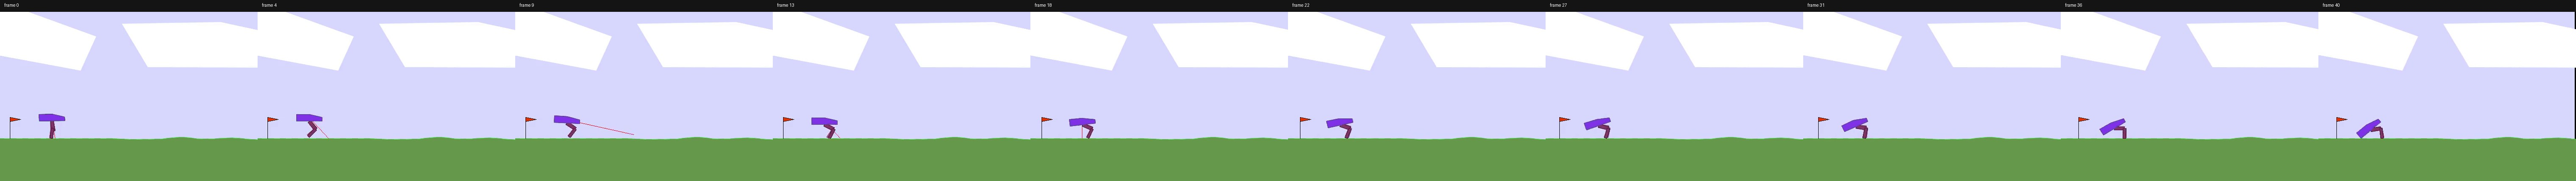

Processing eval_51_step_255000.mp4


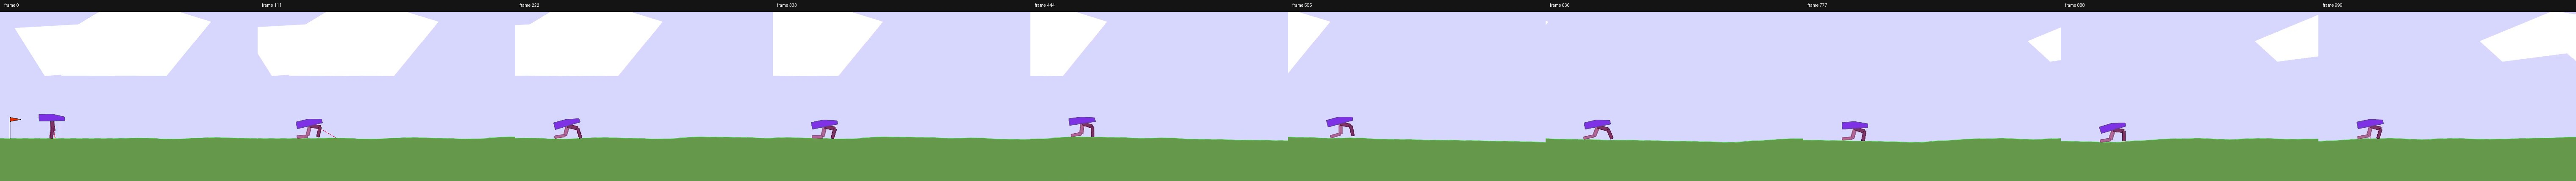

Processing eval_101_step_505000.mp4


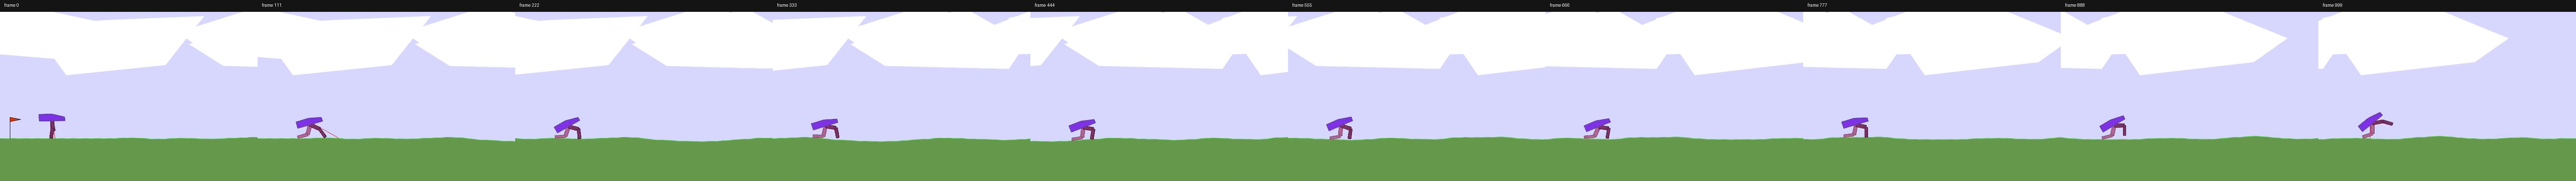

Processing eval_150_step_750000.mp4


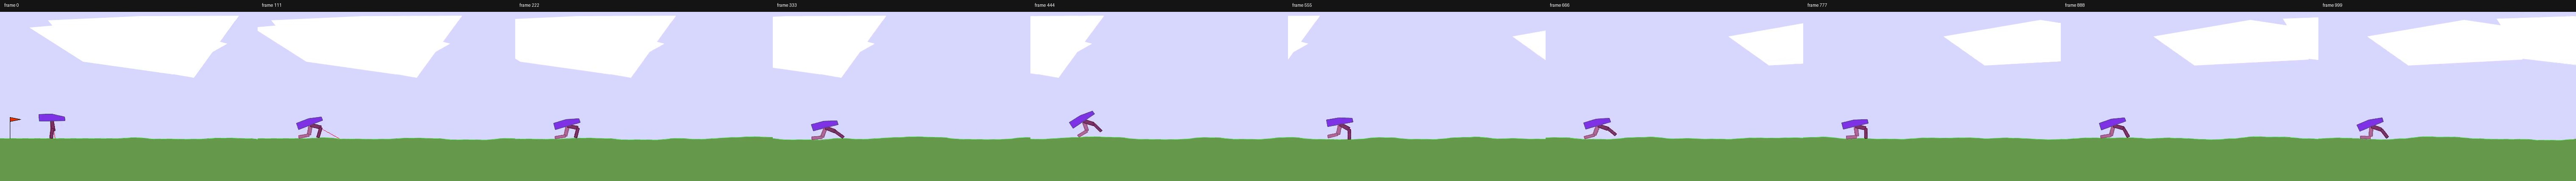

Processing eval_200_step_1000000.mp4


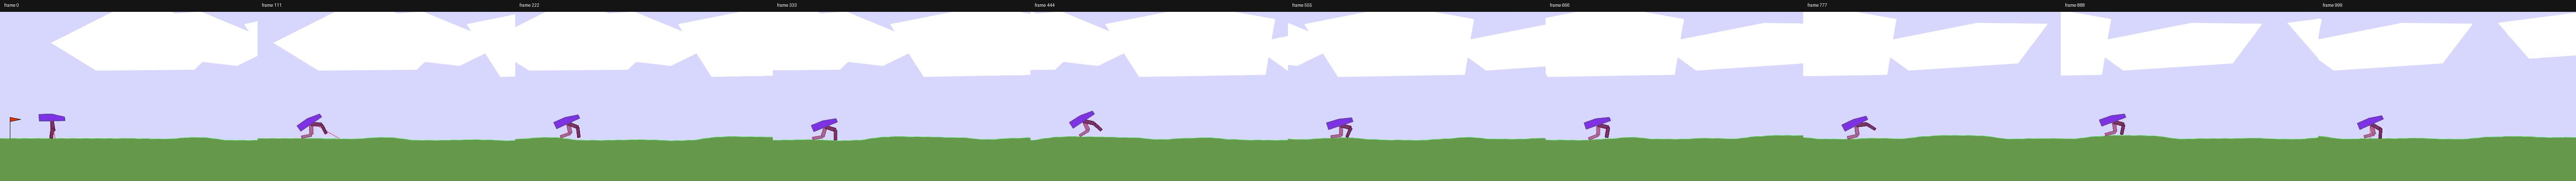

In [29]:
for video_path in select_evenly_spaced(eval_video_path):
    
    print(f"Processing {video_path.name}")
        
    display(Video(str(video_path), embed=True, width=300))
    
    summary_path = create_quick_frame_summary(video_path)
    display(DisplayImage(filename=str(summary_path)))

#### Save the Agent
Save the trained agent.

In [30]:
agent.save("./agents/" + run_name)

For memory management delete old agent and environment (assumes variable names - change if required).

In [31]:
agent.logger.close()    
video_callback.close()  
env.close()
eval_env.close()
del agent, env, eval_env, video_callback

gc.collect()             # the callback and its stored locals form a reference cycle

27

#### Reflection

*Add a reflection on the performance of this agent (<350 words)*

*Add reflection here*

### Task 3 - Overall Reflection
*Write a short (no more than 500 words) reflection on the different agent you have trained, the performance of these agents, and how you might reflect on which one was best.*

#### Extra: Comparing the Agents on the Same Footing
The total (shaped) reward can't be compared between agents because each one was trained on a different reward function. So here every saved agent is run on the **same 10 terrains** (fixed seeds) using the **plain environment reward** (distance, -100 for a fall), plus a few numbers that describe *how* it walks. The Task 2 agent appears twice: at 500k steps (same training length as the other two) and at the end (1M).

- `reached_end` / `fell`: fraction of the 10 episodes
- `base_return`: plain env reward, the thing all agents share (about 364 for the whole course)
- `speed`: distance / time (units per second)
- `torque_used`: mean of sum |action| per step (0 to 4), roughly how hard the motors work
- `jerkiness`: mean of sum |a_t - a_(t-1)| per step, how much the actions flip around
- `hull_tilt_deg`: mean |hull angle| in degrees
- `height_bounce`: std of the hull's height above the ground (lidar ray 0 points straight down)
- `airborne_frac`: fraction of steps with both feet off the ground. Uses Box2D's actual contacts, not the observation flag, because the env's flag can drop to 0 while a foot is still down (it gets cleared whenever *one* contact ends, e.g. sliding over a join between two terrain pieces)
- `hip_corr`: correlation between the two hip angles, i.e. their timing. Near -1 = legs swing in opposite directions (alternating, like normal walking), near +1 = they move together (hopping), near 0 = no clear pattern (e.g. a quarter-cycle offset)
- `leg_balance`: smaller hip swing / bigger hip swing (std of each hip angle). 1 = both legs do the same amount, near 0 = one leg does nearly all the swinging
- `hip_p95_deg`: how far forward the thighs get lifted, in degrees (95th percentile of hip angle; joint limit is 1.1 rad = 63 degrees, Box2D lets it overshoot a little)

In [32]:
agent_names = ["Baseline", "Reward_Exploration", "Custom_Reward_500000_steps", "Custom_Reward"]
eval_seeds = list(range(100, 110))   # 10 terrains, same ones for every agent
end_x = (bipedal_walker_ucd.TERRAIN_LENGTH - bipedal_walker_ucd.TERRAIN_GRASS) * bipedal_walker_ucd.TERRAIN_STEP  # where the env ends the episode

def foot_down(walker, leg_index):
    # ask box2d directly if this lower leg is touching anything (it only collides with the ground)
    return any(edge.contact.touching for edge in walker.legs[leg_index].contacts)

def run_gait_episode(model, seed):
    # plain env, no reward wrapper -> reward here is the base env reward for every agent
    env = bipedal_walker_ucd.BipedalWalkerUCD()
    env = gym.wrappers.TimeLimit(env, max_episode_steps = time_limit)
    obs, _ = env.reset(seed = seed)
    walker = env.unwrapped   # TimeLimit doesnt pass .hull / .legs / .game_over through, so use the raw env
    start_x = walker.hull.position.x
    base_return = 0.0
    prev_action = np.zeros(4)
    log = {"torque": [], "jerk": [], "tilt": [], "height": [], "foot1": [], "foot2": [], "hip1": [], "hip2": []}

    done = False
    while not done:
        action, _ = model.predict(obs, deterministic = True)
        obs, reward, terminated, truncated, info = env.step(action)
        done = terminated or truncated
        base_return += reward
        log["torque"].append(np.sum(np.abs(action)))
        log["jerk"].append(np.sum(np.abs(action - prev_action)))
        prev_action = action
        log["tilt"].append(abs(walker.hull.angle))
        log["height"].append(obs[14] * bipedal_walker_ucd.LIDAR_RANGE)   # ray 0 fraction * range = distance to the ground below
        log["foot1"].append(foot_down(walker, 1))   # legs[1] and legs[3] are the lower legs
        log["foot2"].append(foot_down(walker, 3))
        log["hip1"].append(obs[4])
        log["hip2"].append(obs[9])
    env.close()

    steps = len(log["tilt"])
    distance = walker.hull.position.x - start_x
    foot1 = np.array(log["foot1"])
    foot2 = np.array(log["foot2"])
    swing1, swing2 = np.std(log["hip1"]), np.std(log["hip2"])
    result = {
        "reached_end": float(walker.hull.position.x > end_x),
        "fell": float(walker.game_over),
        "base_return": base_return,
        "distance": distance,
        "speed": distance / (steps / bipedal_walker_ucd.FPS),
        "steps": steps,
        "torque_used": np.mean(log["torque"]),
        "jerkiness": np.mean(log["jerk"]),
        "hull_tilt_deg": np.degrees(np.mean(log["tilt"])),   # env gives radians, degrees are easier to picture
        "height_bounce": np.std(log["height"]),
        "airborne_frac": np.mean(~foot1 & ~foot2),
        "hip_corr": np.corrcoef(log["hip1"], log["hip2"])[0, 1],
        "leg_balance": min(swing1, swing2) / max(swing1, swing2),
        "hip_p95_deg": float(np.degrees(np.percentile(log["hip1"] + log["hip2"], 95))),   # lists, so + joins them: 95th pct over both legs together
    }
    return result, log

rows = []
traces = {}   # keep the step by step log of the first terrain for the plot further down
for name in agent_names:
    model = sb3.PPO.load("./agents/" + name)
    for s in eval_seeds:
        result, log = run_gait_episode(model, s)
        result["agent"] = name
        rows.append(result)
        if s == eval_seeds[0]:
            traces[name] = log

results = pd.DataFrame(rows)
summary = results.groupby("agent").mean(numeric_only = True).loc[agent_names]   # mean over the 10 terrains
summary.round(3)

,reached_end,fell,base_return,distance,speed,steps,torque_used,jerkiness,hull_tilt_deg,height_bounce,airborne_frac,hip_corr,leg_balance,hip_p95_deg
agent,,,,,,,,,,,,,,
Baseline,0.5,0.5,214.366,61.026,2.567,1164.7,2.911,0.756,26.333,0.214,0.435,-0.588,0.462,65.026
Reward_Exploration,0.4,0.6,201.690,60.414,3.216,927.8,2.664,0.734,5.284,0.094,0.352,-0.174,0.223,65.026
Custom_Reward_500000_steps,0.0,1.0,-94.440,1.295,0.881,75.6,3.165,4.607,46.001,0.149,0.477,-0.715,0.526,64.491
Custom_Reward,0.8,0.2,283.478,70.040,2.985,1131.7,3.390,4.255,24.288,0.127,0.261,-0.560,0.776,63.309


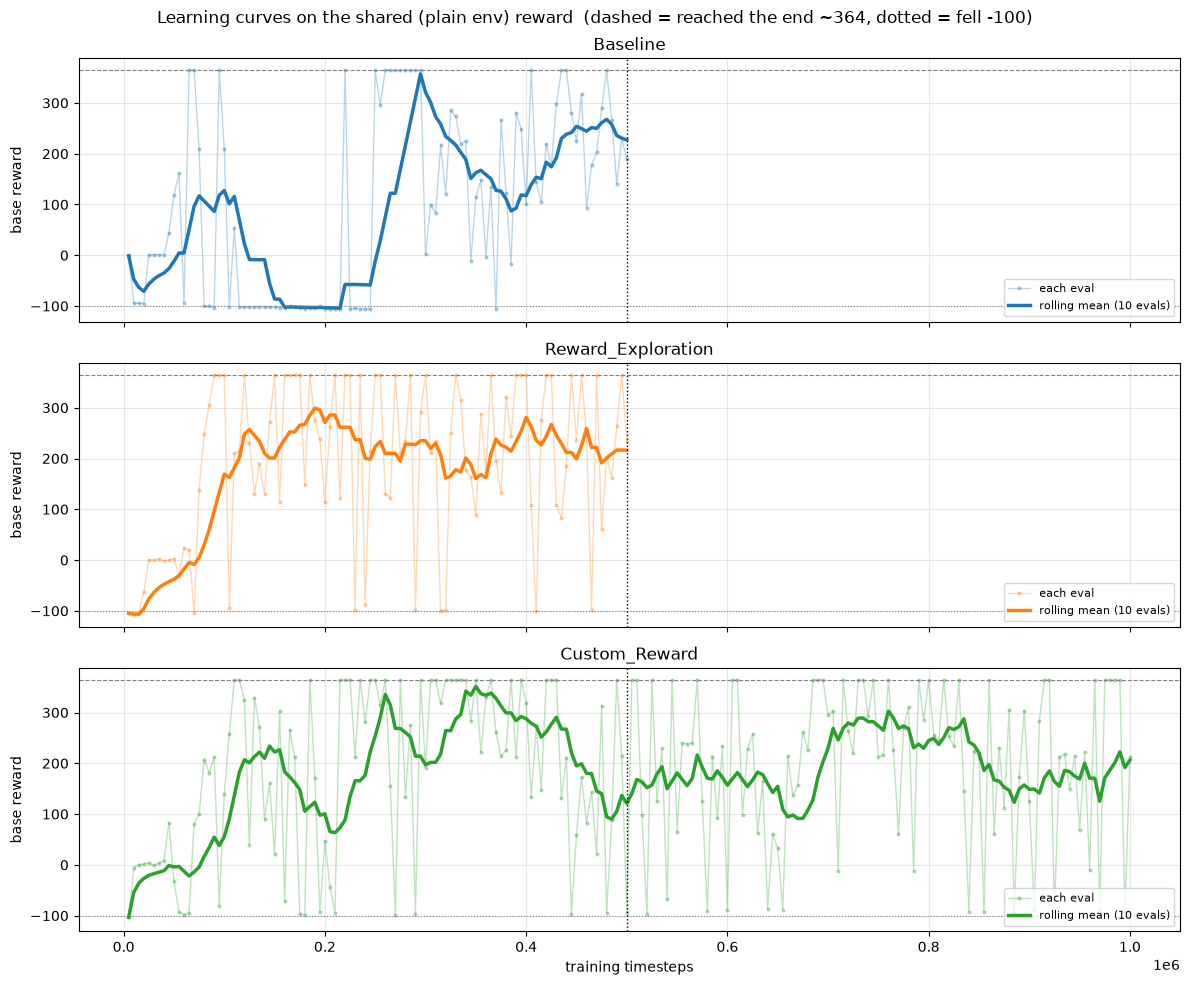

In [33]:
# eval base reward during training for each run (read back from the callback's tensorboard logs).
# using the base part only because thats the bit all 3 rewards have in common.
# one panel per run, otherwise the 3 noisy lines sit on top of each other and you cant read anything.
# faint line = each eval (mean of 3 episodes), thick line = rolling mean over 10 evals (50k steps) to show the trend
from tensorboard.backend.event_processing.event_accumulator import EventAccumulator

run_names = ["Baseline", "Reward_Exploration", "Custom_Reward"]
colours = ["tab:blue", "tab:orange", "tab:green"]
fig, axes = plt.subplots(len(run_names), 1, figsize = (12, 10), sharex = True, sharey = True)
for ax, name, colour in zip(axes, run_names, colours):
    folder = os.path.join(tb_log_path, name + "_eval")
    if not os.path.isdir(folder):
        ax.set_title(name + " (no eval logs - train it first)")
        continue
    acc = EventAccumulator(folder)
    acc.Reload()   # actually reads the event files from disk
    points = acc.Scalars("eval/reward_components/base")
    steps = np.array([p.step for p in points])
    values = pd.Series([p.value for p in points])
    ax.plot(steps, values, color = colour, alpha = 0.3, linewidth = 1, marker = ".", markersize = 4, label = "each eval")
    ax.plot(steps, values.rolling(10, min_periods = 1).mean(), color = colour, linewidth = 2.5, label = "rolling mean (10 evals)")
    ax.axhline(364, color = "grey", linestyle = "--", linewidth = 0.8)   # roughly the full course
    ax.axhline(-100, color = "grey", linestyle = ":", linewidth = 0.8)   # fell straight away
    ax.axvline(500_000, color = "black", linestyle = ":", linewidth = 1)   # where the baseline + task 1 runs stop
    ax.set_ylabel("base reward")
    ax.set_title(name)
    ax.legend(loc = "lower right", fontsize = 8)
    ax.grid(alpha = 0.3)
axes[-1].set_xlabel("training timesteps")
fig.suptitle("Learning curves on the shared (plain env) reward  (dashed = reached the end ~364, dotted = fell -100)")
plt.tight_layout()
plt.show()

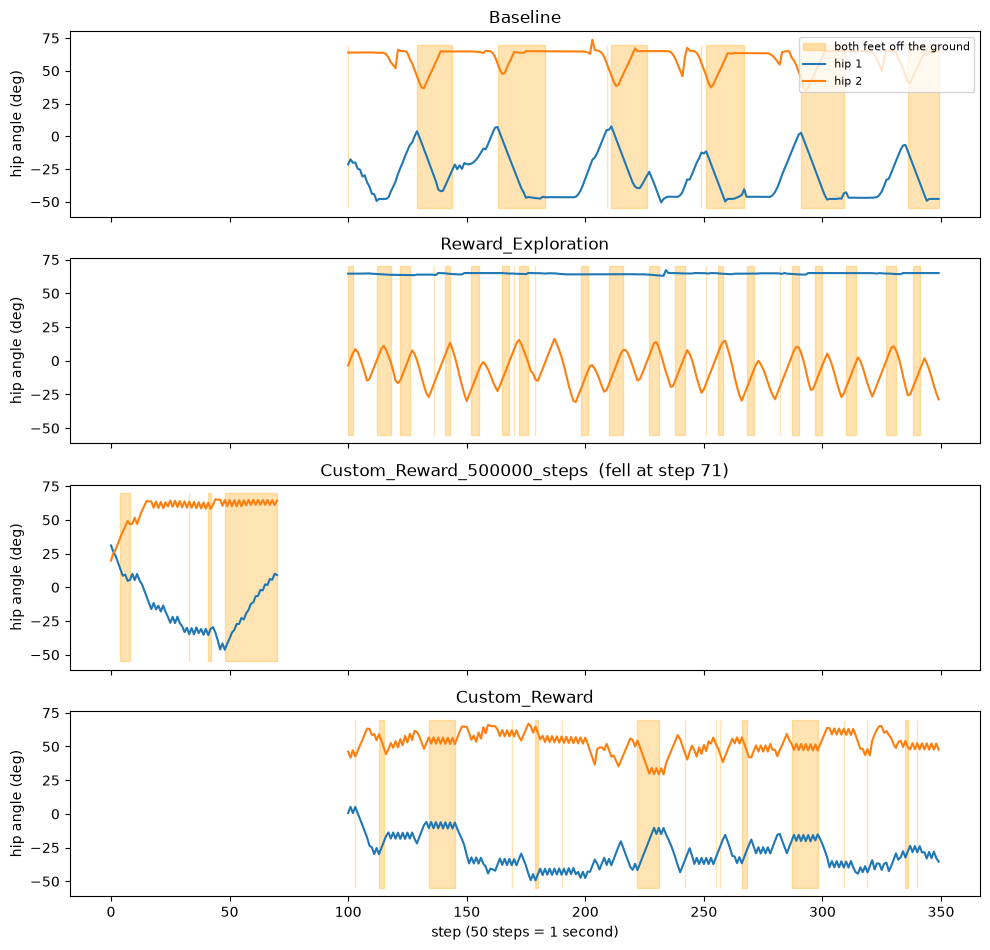

In [34]:
# what the legs are actually doing: both hip angles over 5 seconds of the first terrain,
# orange = both feet off the ground at the same time
fig, axes = plt.subplots(len(agent_names), 1, figsize = (10, 2.4 * len(agent_names)), sharex = True)
for ax, name in zip(axes, agent_names):
    log = traces[name]
    # skip the first 2 sec where its just getting going, unless the episode is too short for that (it fell early)
    window = slice(100, 350) if len(log["hip1"]) > 350 else slice(0, 250)
    hip1 = np.degrees(np.array(log["hip1"])[window])   # radians -> degrees
    hip2 = np.degrees(np.array(log["hip2"])[window])
    steps = np.arange(len(log["hip1"]))[window]
    air = ~np.array(log["foot1"])[window] & ~np.array(log["foot2"])[window]
    ax.fill_between(steps, -55, 70, where = air, color = "orange", alpha = 0.3, label = "both feet off the ground")   # -55..70 just covers the hip range (-46..63 deg)
    ax.plot(steps, hip1, label = "hip 1")
    ax.plot(steps, hip2, label = "hip 2")
    ax.set_ylabel("hip angle (deg)")
    ax.set_title(name + ("  (fell at step %d)" % len(log["hip1"]) if len(log["hip1"]) < 350 else ""))
axes[0].legend(loc = "upper right", fontsize = 8)
axes[-1].set_xlabel("step (50 steps = 1 second)")
plt.tight_layout()
plt.show()

Baseline: episode 1620 steps, reached the end: True, video covers the first 1620 steps -> videos\Baseline.mp4


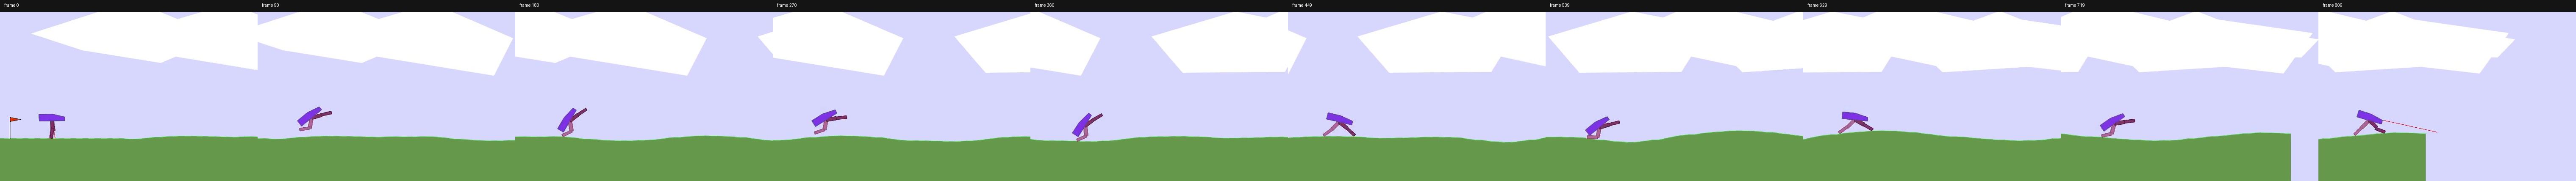

Reward_Exploration: episode 1297 steps, reached the end: True, video covers the first 1297 steps -> videos\Reward_Exploration.mp4


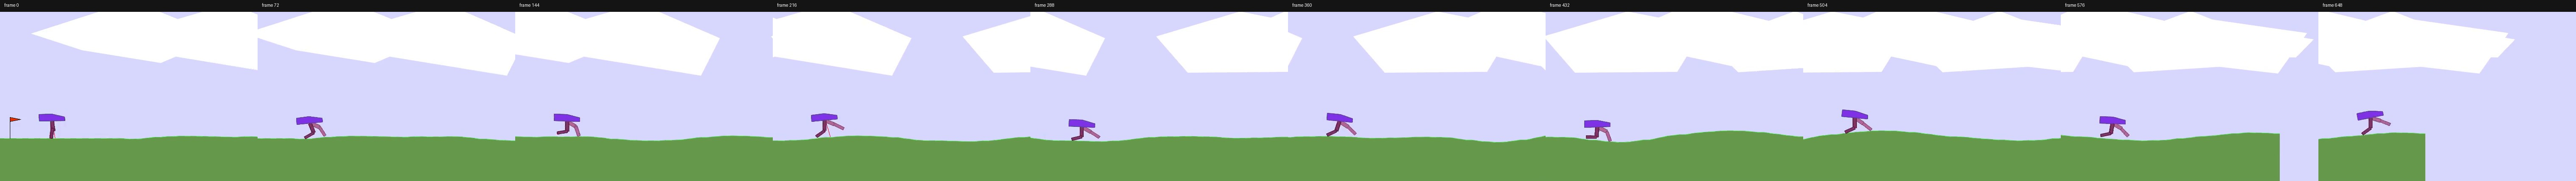

Custom_Reward_500000_steps: episode 71 steps, reached the end: False, video covers the first 71 steps -> videos\Custom_Reward_500000_steps.mp4


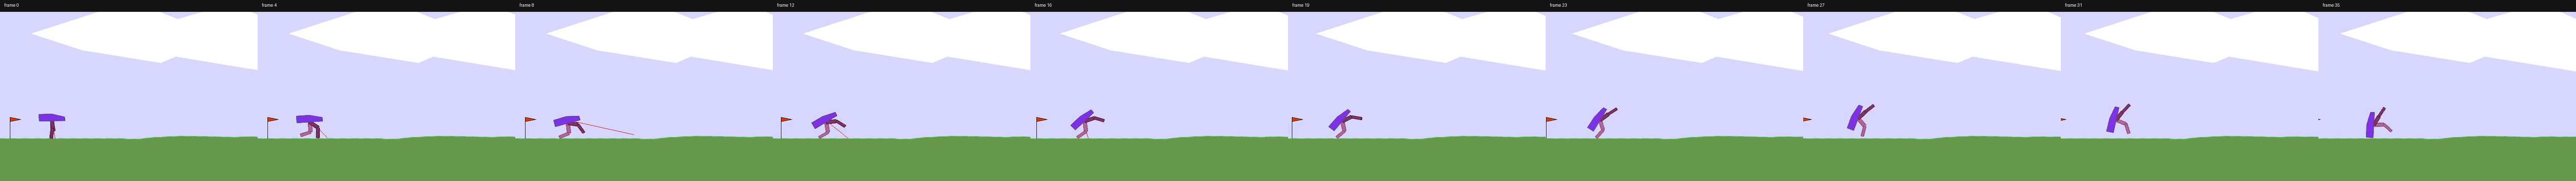

Custom_Reward: episode 1421 steps, reached the end: True, video covers the first 1421 steps -> videos\Custom_Reward.mp4


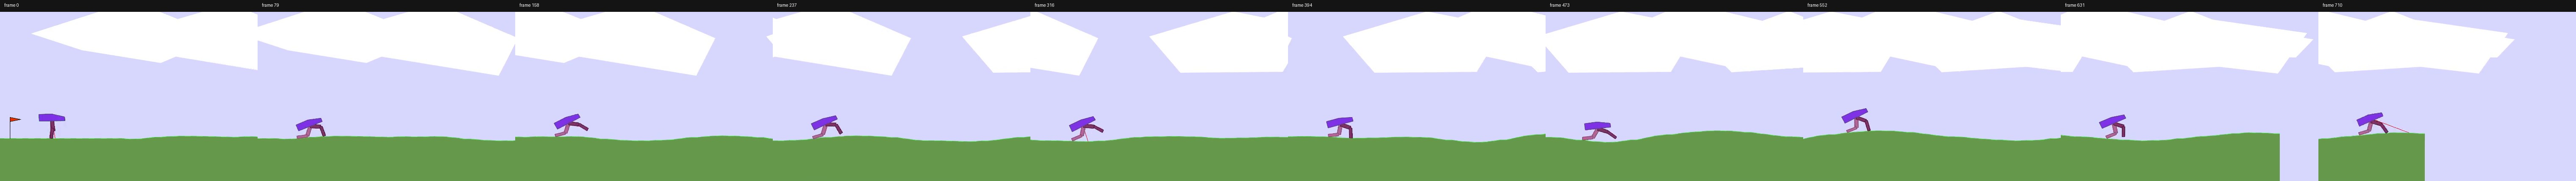

In [35]:
# one video per agent on the same terrain (seed 100), saved to videos/ for the submission zip.
# every 2nd sim step at 25 fps = real time (sim is 50 steps a second).
# capped at 1250 frames (first 2500 steps = 50 sec) - the frame summary function loads the whole video into memory
os.makedirs("videos", exist_ok = True)
for name in agent_names:
    model = sb3.PPO.load("./agents/" + name)
    env = bipedal_walker_ucd.BipedalWalkerUCD(render_mode = "rgb_array")
    env = gym.wrappers.TimeLimit(env, max_episode_steps = time_limit)
    obs, _ = env.reset(seed = 100)
    video_path = Path("videos") / (name + ".mp4")
    step = 0
    done = False
    with imageio.get_writer(video_path, fps = 25) as writer:
        while not done:
            if step % 2 == 0 and step < 2500:
                writer.append_data(env.render())
            action, _ = model.predict(obs, deterministic = True)
            obs, reward, terminated, truncated, info = env.step(action)
            done = terminated or truncated
            step += 1
    reached = env.unwrapped.hull.position.x > end_x
    env.close()
    print(f"{name}: episode {step} steps, reached the end: {reached}, video covers the first {min(step, 2500)} steps -> {video_path}")
    display(DisplayImage(filename = str(create_quick_frame_summary(video_path))))

*Add reflection here*